# ChipWave: A Configurable Platform for AI-Driven Chip Design and PPA Exploration

**Authors:** Xiang Li, Wenyu Sun, Yaqing Lai, Yubo Deng, Yongpan Liu

**Affiliation:** Tsinghua University

**First author and contact:** Xiang Li — [xiang-l24@mails.tsinghua.edu.cn](mailto:xiang-l24@mails.tsinghua.edu.cn)

**Conference representative:** Xiang Li (Graduate student, Tsinghua University)

An open-source, notebook-driven chip-design experiment for IEEE SSCS Code-a-Chip, ISSCC 2027.

## Abstract

An AI-generated circuit is only one outcome of a chip-design experiment.
Researchers also need to change the task, reorganize the engineering team,
and understand how downstream tool feedback changes the next design decision.
These experiments become difficult to interpret when workflow changes also
change the definition of success. We present **ChipWave**, a configurable
platform that separates the **task contract**, the **role-and-tool workflow**,
and **independent acceptance**, connecting them through identified design
artifacts. Researchers can construct qualified tasks, extend built-in roles,
change dependencies, and reuse existing IP without silently changing the
circuit contract. We demonstrate six reference-qualified task variants across
three families, four executable workflow/IP configuration changes, and a
CPU–INT8-accelerator implementation that meets the declared checks at nominal
95 MHz in Sky130HD. Two worked investigations make the platform concrete:
a deliberately faulty accelerator exposes a missing cancellation check, and
a recorded physical-feedback loop revises implementation choices while
retaining the qualified starting design when no proposal improves it.
The released runtime, configurations, checkers and recorded outcomes form a
reusable experimental substrate for studying AI-driven chip design. The
contribution is the ability to construct and inspect these experiments;
workflow superiority is not established by the present case study.

## Setup

The exported [HTML](ChipWave.html) can be read without installing software.
To execute this Notebook, start in the extracted project directory with
Python 3.12 and install the supplied runtime and dependency locks:

~~~bash
python3.12 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements-notebook.lock.txt
python -m pip install -r runtime/requirements.lock.txt
python -m pip install ./runtime
~~~

Open `ChipWave.ipynb` in a Jupyter-compatible editor using that environment.
**Run All** inspects the saved study and lesson outputs; it starts no model calls
or physical implementation. The configuration and circuit exercises in Appendix A
run actual tool checks on saved designs and require the pinned
[EDA tools](toolchain/README.md). New AI experiments additionally require a
user-supplied model account and an explicit execution command.

The [README](README.md) provides Jupyter installation and tool setup.
[Appendix D](#appendix-d) supplies full replay and new-study commands.
Choose a route: [read the case](#platform-results),
[run the minimal exercise](QUICKSTART.md), or
[restore and replay the complete evidence](#appendix-d).
Large raw evidence is losslessly compressed and deduplicated inside this
project; the default Notebook does not require its restoration. Exact storage
counts are in [the evidence index](evidence/index.json). Allow 30 GB free space
for a full restore and measurement scratch, excluding installed tools.

## 1. Introduction

Large language models have made natural-language hardware design a practical
research topic. Evaluating that capability requires more than syntactically
valid RTL. VerilogEval compares generated Verilog against reference behavior
in simulation [1](#ref-1), while RTLLM organizes evaluation around syntax, functionality
and design quality [2](#ref-2). These benchmarks help separate a plausible answer from
a working circuit. They also establish an important principle for a design
platform: the task and its acceptance criteria must be explicit before the
generated implementation is judged.

Tool feedback extends generation into an iterative engineering process.
AutoChip provides a customizable framework that returns compiler and simulation
feedback to conversational models for Verilog repair [3](#ref-3). Chip-Chat examines
human–model collaboration through the design of a processor sent for fabrication
[4](#ref-4). Together, these works motivate studying the interaction between a model,
its engineering instructions and the evidence returned by tools. The
organization of that interaction is itself a design choice: verification may
share the designer's context, use an independent role, or follow a deterministic
check that supplies a concrete report.

Physical implementation adds constraints that functional simulation alone
cannot resolve. OpenROAD develops an open-source digital layout tool chain [5](#ref-5).
The Design Conductor preprint reports autonomous CPU design from requirements
to GDS [6](#ref-6), and ChipAgents' Build-A-Chip-Bench research introduction describes
workload-to-GDS evaluation with functional and physical gates before PPA scoring
[7](#ref-7). Full-flow design and configurable feedback systems thus already exist.
Their results motivate a complementary question: how can a researcher construct
a task, change the workflow used to solve it, and inspect the consequences under
an unchanged definition of success?

This question matters when exploring role specialization or reusing IP.
Adding a verifier also changes the information passed between tasks; replacing
a generated unit with existing IP changes the design entry. If those changes
silently alter the interface, tool constraints or acceptance checks, the
resulting measurements become difficult to interpret. We therefore organize
experiments around three explicit objects: a **task contract**, a configurable
**role-and-tool graph**, and an **independent verdict**. Identified artifacts
connect each proposal to its RTL, reports and physical delivery. This separation
lets a researcher edit the workflow while preserving what the circuit must do
and which implementation was measured.

**ChipWave implements this experimental organization in a reusable public
runtime.** Its contributions are configurable roles and task dependencies;
template-based benchmark construction with reference and fault qualification;
and candidate-bound acceptance and measurement. A five-stage RV32I CPU with a
signed INT8 dot-product accelerator provides the worked circuit. We first
explain the platform architecture (§2), construct qualified tasks (§3), and
change role, dependency and IP configurations (§4). We then follow the
CPU–accelerator through design and physical feedback (§5), examine application
performance and the recorded search outcomes (§6), and conclude with the
platform's reusable contribution (§7). The complete historical comparison
remains in Appendix B. The purpose is to make these design experiments
executable and inspectable; superiority over the cited systems would require
a separate matched evaluation.

### A visual walkthrough

This 36-second animation follows a shared design from intent and a typed
contract through role collaboration, checking, revision and physical delivery.
Press **Play animation**, or select a stage to inspect it.

The sequence illustrates platform responsibilities and feedback; it is not a
recorded experiment. The final layout image comes from the existing
CPU–accelerator case. Playback makes no model or EDA calls.

[Open the animation separately](figures/ChipWave_Workflow.html) ·
[Static platform overview](figures/benchmark_platform.svg).
If a Notebook viewer suppresses interactive output, use either link; in a local
Jupyter environment, run the following cell to display the animation.


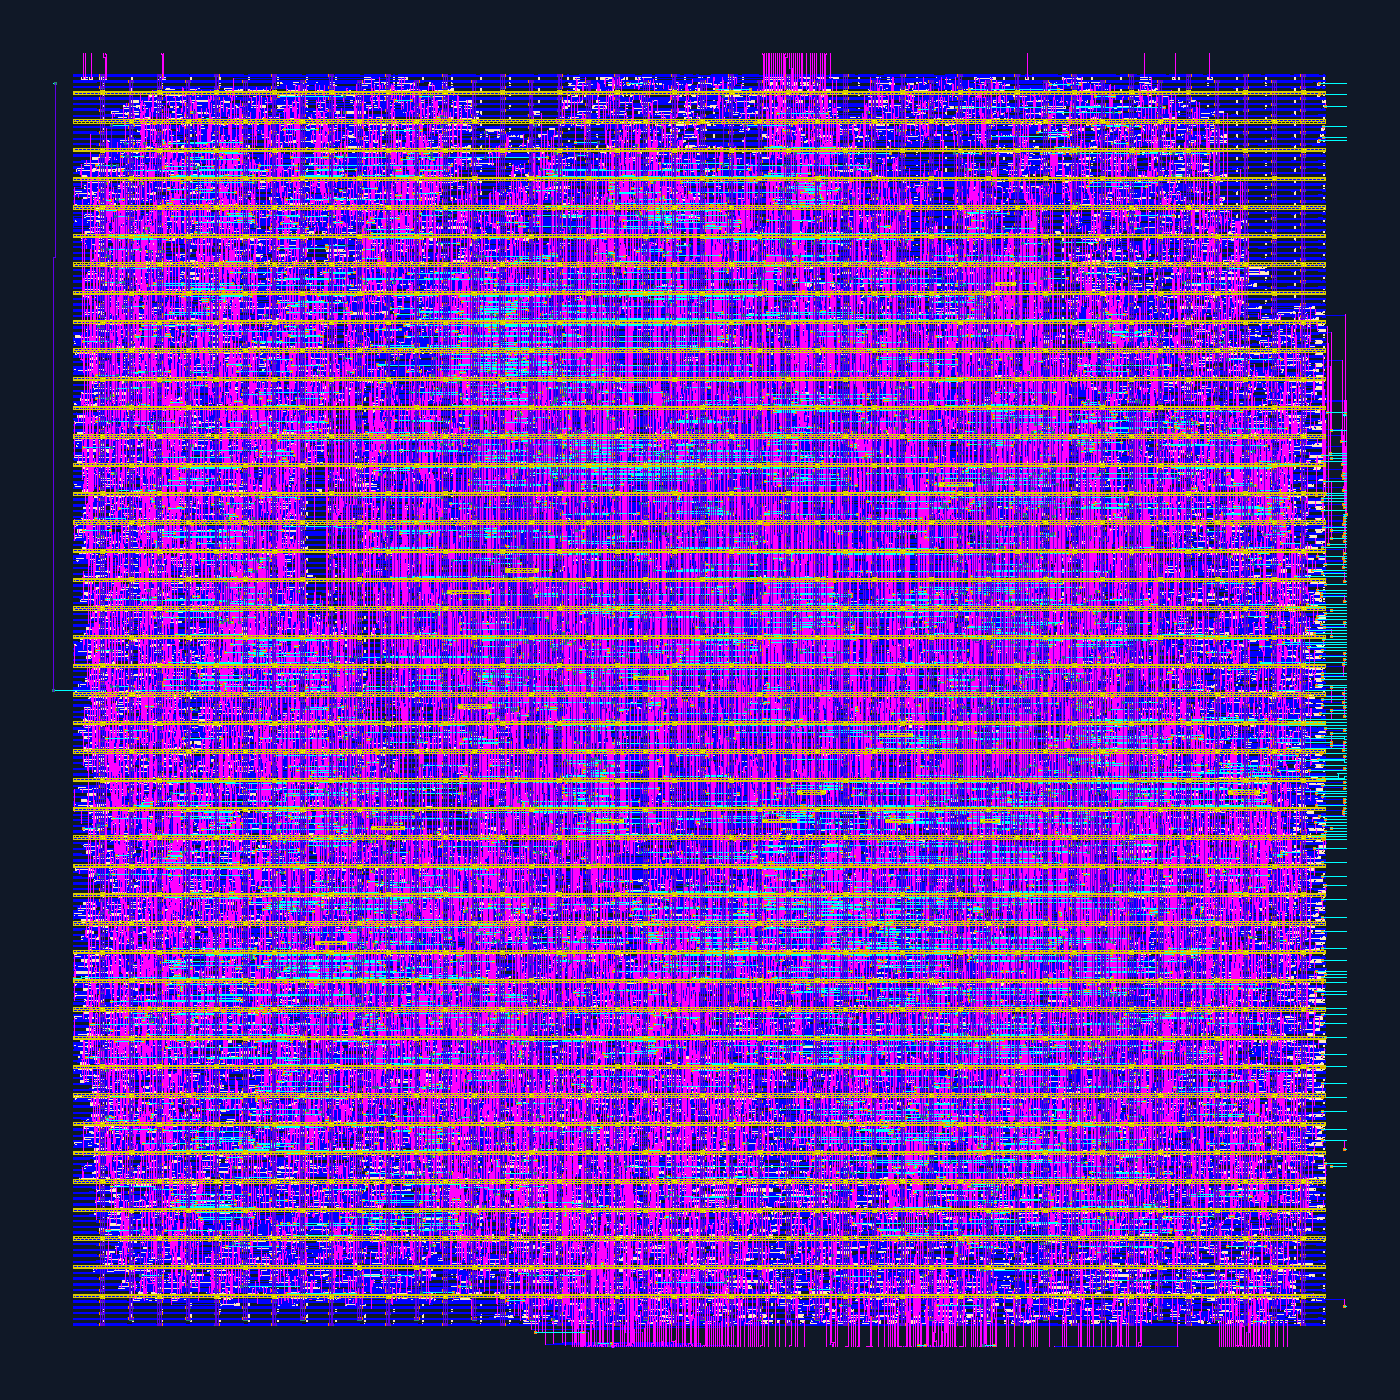

In [1]:
from pathlib import Path
from html import escape
from IPython.display import HTML, display
import warnings

overview_document = Path("figures/ChipWave_Workflow.html").read_text(encoding="utf-8")
# srcdoc keeps this animation offline; IFrame's URL interface is not needed here.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Consider using IPython.display.IFrame instead", category=UserWarning)
    display(HTML(
        '<iframe title="ChipWave: a conceptual multi-agent chip-design workflow" '
        'sandbox="allow-scripts" '
        'style="width:100%;height:1040px;border:0;border-radius:14px;" '
        'srcdoc="' + escape(overview_document, quote=True) + '"></iframe>'
    ))

## 2. Architecture: A Chip-Design Experiment as a Reusable Object

### From a design question to an inspectable experiment

The platform takes a circuit task, a workflow configuration and a resource
budget. It returns a design together with the decisions and checks needed to
interpret that design. A task can enter as a new requirement, as an adaptation
of existing IP, or as an already qualified chip for PPA exploration. These
entry points share the same separation of responsibilities:

| Researcher controls | Platform executes | Experiment returns |
|---|---|---|
| Task family, interface and workload | Contract validation and task qualification | An executable task with a reference and fault-tested checker |
| Roles, tools, dependencies and IP entry | Artifact handoff and configured feedback | Candidate RTL, decisions and tool reports |
| Frozen budgets and acceptance rules | Independent checks and candidate-bound measurement | Qualified or failed outcomes, physical deliveries and costs |

The output is an experiment another researcher can inspect, change and rerun.
The three steps below show how to build it, rather than treating configuration
as a list of software options.

### Task, workflow and acceptance

A configurable flow becomes useful for research only when changing its
organization does not also change what counts as a correct chip. ChipWave
therefore separates three concerns. The **task contract** defines the interface,
behavior, workload and constraints. The **workflow** assigns engineering work to
roles and tools and specifies dependencies and feedback. **Independent acceptance**
checks the produced circuit against the frozen contract.

These are connected through typed artifacts: a task produces an identified RTL
candidate or report, and a downstream task consumes that artifact. A reviewer
can release a proposal for evaluation or return feedback; it cannot make an
unqualified chip pass the final checks. Keeping the proposal, source and measured
result connected also prevents a later edit from borrowing an earlier layout's
successful report.

[![Figure 1. ChipWave separates configurable task/workflow choices from the common acceptance used to compare their outcomes.](figures/benchmark_platform.svg)](figures/benchmark_platform.svg)

**Figure 1. ChipWave separates configurable task/workflow choices from the common acceptance used to compare their outcomes.**

The public runtime provides **15 built-in roles and a 20-task standard
recipe**, covering requirements, CSIR compilation/freezing, RTL, verification,
integration, physical design and export. Here, **CSIR** carries the typed,
machine-checkable external contract attached to a design task. Research flows select and reorganize
these mechanisms through project-local roles and recipes. For example, moving
a verifier behind a deterministic check changes the evidence it receives;
replacing a generated execution unit with licensed RTL IP changes the design
entry. Both remain explicit configuration choices.

| Design decision | Implemented mechanism | Evidence in this Notebook |
|---|---|---|
| Reconfigure the engineering team | Role definitions and Recipe dependencies executed by the same TaskGraph | Four executed role/dependency/IP edits and a recorded feedback path |
| Make tasks reusable | Parameterized requirements, typed contracts, checkers and calibrated reference designs | Six qualified variants from three circuit families |
| Keep comparisons interpretable | Frozen inputs, permissions, budgets, candidate identities and independent gates | Candidate-bound measurement checks and a complete historical ledger |
| Connect process choices to a chip | Common implementation and candidate-bound workload measurement | CPU–accelerator delivery and a 95 MHz feedback case |

A role definition controls its prompt, responsibilities and skill references;
the recipe sets execution model, permissions, tools and task dependencies.
Task, model, workflow, IP and gate settings are frozen within each trial.
A changed configuration starts a different experiment rather than rewriting
its history. [Appendix A](#appendix-a) shows the actual YAML, diffs and executed
handoffs; these capabilities are supplied in the public runtime, not dependent
on the private graphical frontend.

The [standard recipe](runtime/src/chip_nebula/configs/recipes/specification-to-gds.yaml)
and [capability inventory](results/configurable-study/capabilities.json) identify
what is shipped. The focused PPA study enters at an already qualified chip;
it does not rerun requirements and RTL generation for every proposal. Task
construction uses CSIR to validate the typed external behavioral contract;
scoreboards and reference implementations establish its behavior. Complete
behavioral CSIR lowering, automatic hard-macro integration and arbitrary
natural-language task construction are outside the demonstrated scope.

## 3. Step 1: Construct Qualified Design Tasks

The dot-product accelerator introduced in §1 combines arithmetic with a
transaction contract: a computed answer must remain stable under backpressure,
and cancellation must discard obsolete work. A reusable benchmark needs to
make both obligations testable. A generated test that accepts
the reference is not sufficient; it should also reject meaningful wrong designs.
We build this qualification into task construction rather than treating it as
a property automatically supplied by the design agent.

The constructor takes a circuit-family template and parameters such as lane
count, counter width or FIFO depth. It emits a task card, interface, typed CSIR
contract, public development tests, independent final grader, reference
implementation and loadable role/workflow configuration. CSIR checks the typed external
behavioral-contract attachment. Executable scoreboards and reference calibration
establish behavioral and physical validity. The authored templates keep the interface and checker aligned as parameters
change; their validity is then tested by reference and fault qualification.

[![Figure 2. A task becomes evaluable only after its reference, fault detection and physical constraints have been checked.](figures/benchmark_construction.svg)](figures/benchmark_construction.svg)

**Figure 2. A task becomes evaluable only after its reference, fault detection and physical constraints have been checked.**

| Family | Variant | Reference GDS + netlist checks | Area limit (µm²) |
|---|---|---|---|
| counter | counter8 | Qualified | 970 |
| counter | counter16 | Qualified | 1872 |
| fifo | fifo8x4 | Qualified | 2726 |
| fifo | fifo16x8 | Qualified | 9296 |
| dot | dot2 | Qualified | 11036 |
| dot | dot4 | Qualified | 20327 |


Each reference passes function and synthesis checks. At least three different
faulty implementations must compile and then fail the final scoreboard.
A reference completes a 10 MHz physical flow and final-netlist checks; its
standard-cell area sets a limit of **1.25× reference area**, frozen before
evaluating an agent on that task. Three families with two variants each are not six independent
architectures.

The fresh agent demonstrations use `counter8`, `fifo8x4` and `dot2`; their calibrated
physical contracts precede those trials. No fresh demonstration in this benchmark
campaign uses the `dot4` task; the earlier role/IP trials in Appendix B are separate.
The dot4 reference was calibrated later and supplies task-validity evidence
only; its chronology and calibration costs are retained in Appendix B.

The public checkers support reproduction. During scoring, reference RTL,
held-out tests and other trials are outside the agent's filesystem.
An invalid task and an unsuccessful agent design are different outcomes.

In [2]:
import json
from pathlib import Path
ROOT = Path.cwd()
assert (ROOT / "scripts").is_dir(), "Start Jupyter from the project directory."
DATA = ROOT / "results" / "benchmark-study"
study = json.loads((DATA / "analysis.json").read_text())
for task in study["benchmark"]["rows"]:
    print(task["task"]["id"], "reference qualified" if task["reference_gds"] else "reference incomplete")

counter8 reference qualified
counter16 reference qualified
fifo8x4 reference qualified
fifo16x8 reference qualified
dot2 reference qualified
dot4 reference qualified


### A task-construction discovery: cancellation after the answer is ready

A ready/valid accelerator can produce the right arithmetic answer yet mishandle
cancellation while its response is held under backpressure. We constructed a
fault that ignores cancellation only in that response phase. The first grader
accepted it. Adding held-response cancellation and asynchronous-reset scenarios
rejected the same faulty circuit, while the reference continued to pass.

| Task | First grader on targeted fault | Extended grader on same fault | Reference with extended grader |
|---|---|---|---|
| dot2 | Accepted (gap exposed) | Rejected | Passed |
| dot4 | Accepted (gap exposed) | Rejected | Passed |


The reference RTL and interfaces were unchanged. The existing dot2 GDS also
passed the extended final-netlist check, without a new physical implementation.
Both original verdicts and the pre-agent checker revision are retained. This is
why task qualification is part of the platform: a generated benchmark must be
tested before its agent scores can be trusted.

[Checker revision and qualification evidence](results/benchmark-study/checks/checker-revision-v2/qualification.json).

### From task validity to a fresh design

Once a task is qualified, a new agent receives its requirements and permitted
development material, not the reference answer. The preselected counter8,
fifo8x4 and dot2 demonstrations use fresh designer/verifier contexts and a shared
1,200-second frontend budget. Each functionally qualified design receives at
most one physical implementation. These three examples show the same method
applied beyond the CPU operator; they are not a large generalization study.

| New task | Frontend terminal | Independent function | Physical result |
|---|---|---|---|
| counter8 | True | Qualified | Qualified |
| fifo8x4 | True | Qualified | Qualified |
| dot2 | True | Qualified | Qualified |


A new requirement can therefore change the task without changing the separation
between designer and evaluator. [Appendix A](#appendix-a) makes that operation
concrete with a parameter edit and a short cancellation experiment.

## 4. Step 2: Compose Agent Workflows

### 4.1. Roles and task dependencies

ChipWave represents engineering work as a graph of role and tool tasks.
A role supplies instructions and responsibilities; a Recipe binds its inputs,
outputs and dependencies. The TaskGraph executes ready tasks and delivers
their identified artifacts to downstream consumers. For the dot-product
design, an independent verifier needs both the candidate RTL and relevant
tool evidence. In the executed example below, the initial configuration runs
**designer → verifier → tool check**. A dependency edit changes this to
**designer → tool check → verifier**. The verifier now receives the fixed
checker's report before forming its verdict; the circuit contract stays fixed.

This is a real TaskGraph replay using saved generated RTL and real tool checks.
It demonstrates configurable execution, not a new AI design or a quality gain.

[![Figure 3. Four executed configuration edits change roles, dependencies and IP entry while retaining explicit checks; saved RTL replay.](figures/study_tutorial.svg)](figures/study_tutorial.svg)

**Figure 3. Four executed configuration edits change roles, dependencies and IP entry while retaining explicit checks; saved RTL replay.**

The decisive input is the following actual YAML excerpt from the executed recipe. The verifier consumes the audit report only after its verdict passes. The complete dependency edit and all task fields are linked below.

~~~yaml
tasks:
  verifier:
    inputs:
      smoke:
        type: verification.report
        from: $tasks.audit.outputs.report
        release:
          field: verdict
          equals: passed
~~~

[Configuration diff](results/configurable-study/tutorial/03-check-before-review/configuration.diff) · [Complete recipe](results/configurable-study/tutorial/03-check-before-review/project/.chip_nebula/recipes/tutorial.yaml) · [Executed results](results/configurable-study/tutorial/summary.json)

The same project-local mechanism loads a custom designer, adds its verifier,
changes check order, or connects the licensed processing element through an
adapter. All four saved lessons completed their declared tasks. Existing IP
still needs interface adaptation and the same functional checks.

Appendix A supplies the commands, complete configuration edits and circuit
exercise. The portable runtime includes the roles and TaskGraph used here;
the private graphical frontend is not needed to reproduce these operations.

### 4.2. Candidate-bound measurement

Changing the workflow is useful only if its outputs remain attributable. The
measurement loader checks the selected delivery, source commit, netlist, OpenDB,
SPEF, clock constraints and Liberty identity before accepting measurement inputs.
A report from an earlier physical candidate cannot simply be attached to a new
netlist. This is a concrete guard used by the workload measurement path.

The compact distribution stores large raw views separately. With Python 3.12,
first restore the local evidence (30 GB free working space recommended), then
exercise the loader on copies of two saved deliveries:

~~~bash
python scripts/evidence_store.py restore
python scripts/identity_lesson.py --output ../identity-lesson
~~~

The lesson
accepts the original set, then deliberately introduces three mismatches and
checks that each is rejected. No model, simulation or physical implementation
is started; the original evidence is unchanged.

| Controlled input | Measurement loader |
|---|---|
| Original matched delivery | Accepted |
| Netlist from a different physical candidate | Rejected |
| Clock changed without a new delivery | Rejected |
| Measurement manifest names another delivery | Rejected |
| Original delivery restored | Accepted |


[Actual lesson receipt](results/teaching/identity/lesson.json) ·
[Runnable lesson](scripts/identity_lesson.py).
These are deliberately injected mismatches, not additional chip-design samples
or a proof against an attacker who can rewrite every trusted manifest.

## 5. Step 3: Close the Loop with Physical Feedback

### 5.1. Architecture and transaction contract

We use a five-stage RV32I CPU and a four-lane signed INT8 dot-product accelerator
because the pair connects an understandable workload to nontrivial integration
and physical-design decisions. The CPU runs control and data movement; the
accelerator replaces repeated software multiply–accumulate work. This small
operator is the NPU in the case study, not a general neural-network processor.

Two 32-bit CPU operands each hold four signed 8-bit lanes. The accelerator
forms four 16-bit products, adds them in 17-bit pairs, then returns a signed
32-bit result. Registers separate multiplication, pair addition and final
reduction; the response is held until accepted. This trades a short, explicit
multi-cycle transaction for a wide combinational operation in the CPU pipeline.
The [released operator RTL](released_design/rtl/npu/nebula_npu_dot4.sv) exposes
these choices directly.

The interface is as important as the arithmetic. A request must be accepted at
the right time, a result must survive backpressure, and cancellation must prevent
obsolete work from retiring. Those obligations make the system a useful case
for studying verification roles and feedback across design stages. Instruction
and data memories remain outside the routed core.

[![Figure 4. The worked CPU–accelerator system couples useful INT8 arithmetic to request, cancellation, backpressure and retirement contracts.](figures/cpu_npu.svg)](figures/cpu_npu.svg)

**Figure 4. The worked CPU–accelerator system couples useful INT8 arithmetic to request, cancellation, backpressure and retirement contracts.**

The case combines AI-assisted RTL development with engineering-defined
contracts and tests. CPU integration, synthesis and physical implementation
produce the qualified starting chip used below. The PPA experiment resumes
from that frozen design, while the task-building examples in §3 exercise
separate small designs from requirements.

### 5.2. PPA workflow and acceptance

The platform can also enter at a qualified CPU–accelerator and organize a PPA
exploration. An optimizer proposes a legal action, a reviewer can examine it,
and tools independently determine the result. The report returns to the
optimizer with the identity of the evaluated candidate. The reader can follow
what changed and why without treating an agent's approval as a physical result.

The diagram shows available configurations. The worked trace is the **first
session in the frozen execution order**, the first conditional-review session
(F2-1), selected by chronology rather than outcome. It used gpt-6.1-sol with high reasoning, 1,200 aggregate role
seconds and three accepted candidate slots; deterministic EDA waiting was
separate. This is a saved AI-driven search, not a new experiment or an equal-Token
comparison. The CPU, cycle contract and independent checks remained frozen.

[![Figure 5. Available PPA workflow configurations. The worked session follows the reviewed path at all three candidates; bypass is a configured capability.](figures/benchmark_ppa_workflows.svg)](figures/benchmark_ppa_workflows.svg)

**Figure 5. Available PPA workflow configurations. The worked session follows the reviewed path at all three candidates; bypass is a configured capability.**

The shared action library offers request-qualified operand isolation and an
explicit signed 18-bit reduction, plus bounded implementation parameters.
Four signed INT8 products can sum to 65,536: 18 bits retain that value before
sign extension to 32 bits. Operand isolation may reduce idle switching but adds
logic. Each action combination passed the recorded correctness/equivalence
checks before search; neither action has a guaranteed PPA benefit.

The target is a 10.526 ns clock (nominal 95 MHz), Sky130HD TT/25°C/1.8 V,
0.1 ns uncertainty and 0.5 ns input/output delays including reset. OpenROAD uses
NUM_CORES=2; auxiliary tools retain their recorded defaults. Function, equivalence,
workloads, setup/hold, electrical limits and the stated DRC/LVS checks gate
acceptance. Q is standard-cell area ratio times the geometric mean of three
modeled workload-energy ratios; lower is better and the common start has Q=1.

**Physical-check scope:** the bundled KLayout runset enables BEOL and
OFFGRID checks and disables FEOL checks. LVS uses the bundled Sky130 deck.
This is a routed-core implementation under these declared checks, not full
foundry signoff. Memories remain outside the routed core. Energy uses
Liberty/SPEF and zero-delay gate activity, without SDF/glitch or silicon-power
measurement. [Exact DRC configuration](toolchain/orfs/flow/platforms/sky130hd/drc/sky130hd.lydrc).

## 6. Results and Discussion

The central question is whether the platform makes a chip-design experiment
both editable and interpretable. We first examine task and workflow evidence,
then follow a real physical-feedback decision, and finally inspect the chip
that anchors the experiment. Circuit performance establishes application value;
it is not used as a proxy for the quality of the agent organization.

<a id="platform-results"></a>

### 6.1. What can a researcher change and verify?

The platform evidence spans task construction, workflow composition and
measurement. Each result below answers an operation a researcher can perform.
The qualifications and limits belong to that operation, not to a universal
claim that any agent team or generated benchmark will work.

| Research operation | Observed result | Meaning for reuse |
|---|---|---|
| Instantiate and qualify a task | Six reference-qualified variants; three preselected fresh task designs passed their checks | The same construction method supports three authored circuit families |
| Test the evaluator itself | Held-response cancellation fault accepted by the first grader, rejected after extension | Reference success alone does not establish task validity |
| Reorganize engineering work | Four role/dependency/IP lessons completed with real TaskGraph execution and tool checks on saved RTL | Configuration changes are executable, with unchanged circuit acceptance |
| Bind a measurement to a design | Original delivery accepted; injected netlist, clock and identity mismatches rejected | A new candidate cannot inherit an unrelated successful measurement |

The cancellation example in §3 is especially instructive. It changed the
**evaluation task**, not the reference circuit: the added scenario made a
previously invisible protocol error observable. The dependency example in §4
changed the **engineering process**, not the task: the verifier received a
real checker report earlier. These distinct edits illustrate why the platform
keeps task construction and workflow organization separate.

### 6.2. Following physical feedback back to a decision

The first available evaluated session, **F2-1**, supplies this trace.
The optimizer chooses from the shared action library and implementation settings.
The review branch permits a proposal to reach the tools; the independent gates
decide whether the resulting chip can earn a score. Both positive and negative
outcomes return to the same optimizer before its next decision.

| Candidate | RTL action | Implementation settings | Released path | Qualified Q / failure |
|---|---|---|---|---|
| 1 | Operand isolation + Narrow reduction | Util 40%; density 0.55; ABC area 0; repair 0% | AI review | Ineligible: physical-flow failure, timing |
| 2 | Narrow reduction | Util 40%; density 0.55; ABC area 0; repair 0% | AI review | Ineligible: electrical limits |
| 3 | Narrow reduction | Util 40%; density 0.55; ABC area 0; repair 10% | AI review | 1.0112 |

Candidate 1 failed qualification (physical-flow failure, timing). The next proposal disabled operand isolation. Candidate 2 failed qualification (electrical limits). The next proposal changed electrical repair margin from 0% to 10%. All other action and implementation settings stayed fixed in each transition.
The trace documents the response to feedback; every resulting chip must still pass all independent gates.

Candidate 3 passed all gates. Relative to the start, its standard-cell area changed by +0.11% and its geometric-mean model-estimated workload energy by +1.01%, giving Q = 1.0112. The session retained the common start with Q = 1.0000.

A chip can pass every engineering check and still be a worse choice. Here,
the later candidate passes the gates, while its combined area–energy cost
remains above the starting design. The retained incumbent makes this finding
useful: the reader keeps the qualified starting chip and can inspect the full
search to understand why the new candidate did not replace it. This lesson
comes from this session; it does not establish a winner among workflows.

Candidate evaluation records:
[first proposal](results/benchmark-study/ppa/F2-1/candidates/01/evaluation.json),
[second proposal](results/benchmark-study/ppa/F2-1/candidates/02/evaluation.json),
[third proposal](results/benchmark-study/ppa/F2-1/candidates/03/evaluation.json).
The [recorded task graph](results/benchmark-study/ppa/F2-1/taskgraph.json)
connects role reports, proposals and feedback.

The useful platform behavior here is report-driven revision and retention of
the qualified starting design when a new candidate is worse. The trace does not
prove that the reviewer was necessary. All three proposals were reviewed;
the conditional bypass was not exercised in this session.

**Context of this example:** across the complete historical nine-session study,
9 of 27 new candidates qualified and none improved on the common start. F1 and
F2 realized the same review schedule. The result supports the demonstrated
execution mechanism, not workflow superiority or a measured PPA improvement.
[Appendix B](#appendix-b) retains all nine sessions, failed outcomes, costs,
search curves and 100 MHz challenges.

### 6.3. Application value of the worked chip

The accelerator's application value is measured independently of workflow
organization. Across DOT64, GEMM8 and CONV3, the mean cycle speedups are
**7.55–7.79×** against RV32I software multiplication
without the M extension. These results describe the accelerator's application
value; they are not an improvement caused by adding agents.

| Workload | Mean software cycles | Mean accelerated cycles | Mean cycle speedup |
|---|---|---|---|
| DOT64 | 6773.0 | 870.7 | 7.79× |
| GEMM8 | 54279.7 | 7036.0 | 7.71× |
| CONV3 | 34550.0 | 4575.3 | 7.55× |


Each workload uses the same program and input data across three testbench seeds;
the seeds vary memory-bus timing, not the workload dataset. The means average
the paired scalar/accelerated runs under those timing conditions. The cycle
boundary includes reset, setup, packing, loads and stores through committed
completion, rather than timing only the arithmetic operator. The power study later uses explicitly defined activity
windows. Separating these measurements keeps a useful application result from
being mistaken for workflow efficiency.

The [workload results](results/operators-first/summary.json) retain per-seed
cycles and outputs. After installing the pinned tools, `python scripts/reproduce.py --output ../cpu-checks` reruns the supplied CPU/NPU functional suite; the
candidate-bound power replay is a separate command in Appendix D.

### 6.4. Physical delivery

The frozen starting chip meets the declared functional and physical gates.
The following measurements refer to the routed block, with instruction and
data memories outside its boundary.

The qualified common starting chip provides the physical anchor for this example.

| Clock target | Cell area (µm²) | Routed-block die footprint (µm²) | Setup / hold slack (ns) |
|---|---|---|---|
| 95 MHz | 161954 | 377672 | 0.193 / 0.114 |

[Delivered source and measurement record](results/benchmark-study/baseline/common/campaign-evaluation.json).

[![Figure 6. Actual GDS routing view of the common 95 MHz CPU–accelerator core; the declared-check scope is stated above.](figures/benchmark_layout_0.png)](figures/benchmark_layout_0.png)

**Figure 6. Actual GDS routing view of the common 95 MHz CPU–accelerator core; the declared-check scope is stated above.**

### 6.5. Scope and limitations

The task-construction results establish six qualified variants from three
authored families, including a checker revision that exposed held-response
cancellation. The workflow lessons establish executable role, dependency and
IP changes; the identity lesson exercises the actual measurement loader.
These mechanisms support reproducible experimentation without establishing
that more roles produce better chips.

The circuit evidence covers a small dot-product accelerator, one CPU and one
PVT corner. The software comparison uses RV32I without the M extension, and
power is a model estimate under the activity and physical-check scope in §5.2.
The historical PPA study has three repeats per configuration and equal role-time
limits, not equal Token consumption. Its bounded action space and realized
review schedules limit conclusions about broader agent organizations.
A native-Codex comparison and cross-task learning remain open questions;
Appendix C records the excluded development diagnostics.

Task construction relies on authored templates, references and scoreboards;
complete behavioral CSIR lowering and arbitrary natural-language generation of
trustworthy tasks remain beyond the demonstrated implementation. The released
runtime contains the components used here; the private graphical frontend is
not required for these experiments.

## 7. Conclusion

ChipWave turns the organization of a chip-design experiment into a reusable
research object. Task contracts define the circuit problem, role-and-tool graphs
define the engineering process, and independent checks attach a verdict to the
implementation actually delivered. Six qualified task variants, executable
workflow changes and a CPU–accelerator GDS demonstrate these mechanisms in use.

A researcher can reuse a qualified task, substitute a role or IP entry, and
follow the resulting candidate through the same gates. The worked design
illustrates why those gates matter: cancellation must remain correct, electrical limits must
hold, and a qualified revision still needs to justify replacing its starting
chip. By releasing the configurations, circuit exercises and recorded outcomes,
this Notebook gives researchers a concrete starting point for constructing
tasks and studying those decisions in their own workflows.

## References

<a id="ref-1"></a>
[1] M. Liu, N. Pinckney, B. Khailany and H. Ren. [VerilogEval: Evaluating Large Language Models for Verilog Code Generation](https://arxiv.org/abs/2309.07544). ICCAD, 2023.

<a id="ref-2"></a>
[2] Y. Lu, S. Liu, Q. Zhang and Z. Xie. [RTLLM: An Open-Source Benchmark for Design RTL Generation with Large Language Model](https://arxiv.org/abs/2308.05345). ASP-DAC, 2024.

<a id="ref-3"></a>
[3] J. Blocklove et al. [Automatically Improving LLM-based Verilog Generation using EDA Tool Feedback](https://arxiv.org/abs/2411.11856). AutoChip; manuscript accepted for ACM TODAES, 2025.

<a id="ref-4"></a>
[4] J. Blocklove, S. Thakur, B. Tan and H. Pearce. [Chip-Chat: Challenges and Opportunities in Conversational Hardware Design](https://arxiv.org/abs/2305.13243). MLCAD, 2023.

<a id="ref-5"></a>
[5] T. Ajayi et al. [OpenROAD: Toward a Self-Driving, Open-Source Digital Layout Implementation Tool Chain](https://austinrovin.ski/pubs/ajayi2019openroad.pdf). 2019.

<a id="ref-6"></a>
[6] The Verkor Team. [Design Conductor: An agent autonomously builds a 1.5 GHz Linux-capable RISC-V CPU](https://arxiv.org/abs/2603.08716). arXiv preprint, 2026.

<a id="ref-7"></a>
[7] S. Gunukula, J. Y. Wang and K. Zhang. [Introducing Build-A-Chip-Bench: from workload specification to GDS](https://chipagents.ai/research/build-a-chip-bench). ChipAgents Research introduction, October 2026.

### Software, notebook and licensing resources

The implementation uses [OpenROAD](https://github.com/The-OpenROAD-Project/OpenROAD),
[OpenROAD-flow-scripts](https://github.com/The-OpenROAD-Project/OpenROAD-flow-scripts),
[Yosys](https://github.com/YosysHQ/yosys),
[Icarus Verilog](https://github.com/steveicarus/iverilog),
[Verilator](https://github.com/verilator/verilator) and [KLayout](https://www.klayout.de/).
Versions, resource identities and IP origins are supplied in the tool locks and
[THIRD_PARTY_NOTICES.md](THIRD_PARTY_NOTICES.md).

The [CABAgent competition Notebook](https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io/blob/main/VLSI26/accepted_notebooks/CABAgent/CABAgent.ipynb)
informed the problem–method–worked-example presentation; no figures or code
are copied. The [Code-a-Chip program](https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io)
provides the submission requirements.

Original submission material and the selected runtime use [Apache-2.0](LICENSE).
Third-party licenses remain applicable; the bundled Sky130 DRC runset is
[GPLv3](toolchain/licenses/GPL-3.0.txt), as detailed in the notices.

<a id="appendix-a"></a>

## Appendix A. Executable configuration and circuit experiments

Change one configuration at a time: task parameters, a role, verifier
participation, tool-check order, then execution-unit/IP integration.

~~~bash
python scripts/build_benchmark.py --family counter --width 16 --output ../counter16-task
python scripts/qualify_benchmark.py --task ../counter16-task
~~~

These account-free commands construct a task and check its reference and
mutants locally. Physical calibration is still required before scoring a design.
The generated project contains real role and Recipe YAML.

~~~bash
python scripts/workflow_tutorial.py --output ../workflow-lessons
~~~

The four workflow lessons retain their actual configuration diffs, task order
and real tool outputs. They replay saved generated RTL; they do not count as
fresh AI design. The IP lesson uses the licensed processing element and adapter.
Changing a prompt, dependency or gate creates a new frozen experiment.

### Try the contract: when is a result allowed to leave?

Before changing a workflow, try the circuit contract it must protect. The
published two-lane reference computes **2 × 4 + (−3) × 5 = −7**. A response is
delivered only on a rising edge with both `rsp_valid` and `rsp_ready` high.

Predict two outcomes: should the result change while the receiver is stalled?
If cancellation arrives on the same edge as readiness, should that result leave?
The contract says **hold the result**, and **cancellation wins**.

~~~bash
python3 scripts/handshake_lesson.py --output ../handshake-lesson
~~~

Run from the extracted project with Python 3.12 and Icarus Verilog on PATH.
No third-party Python packages, model account or full physical flow are needed.
Choose a new output directory. The command retains assertions, CSV/VCD traces,
source identities and logs, and checks that the published cancel-ignored mutant
compiles but fails. This short teaching trace does not replace the full grader.

The trace below is from **real RTL simulation of the published reference**,
not an AI-generated design or a new scored experiment. Samples are taken just
before each rising edge; response data matters only while `rsp_valid` is high.

[![Figure A1. Backpressure holds −7; cancellation suppresses delivery. The trace is measured, not a conceptual waveform.](figures/handshake_lesson.svg)](figures/handshake_lesson.svg)

**Figure A1. Backpressure holds −7; cancellation suppresses delivery. The trace is measured, not a conceptual waveform.**

| Edge | Observed event | What the contract requires |
|---|---|---|
| 1 | A accepted | Signed two-lane operands captured |
| 4–5 | A held at −7 | No delivery while the receiver is stalled |
| 6 | A delivered | Valid and ready are both high |
| 8 | B cancelled while busy | Cancellation also blocks a new request |
| 14 | C cancelled with receiver ready | Cancellation wins over delivery |
| 16 | Reset asserted | Reset suppresses both handshakes |

The actual delivered-edge list is **[6]**. The cancel-ignored mutant is rejected. A plausible arithmetic answer alone would miss this protocol error; this is why task construction includes behavioral checks.

In [3]:
# Optional real simulation; default execution reads saved results without tools.
RUN_HANDSHAKE_LESSON = False
if RUN_HANDSHAKE_LESSON:
    import subprocess, sys, tempfile
    lesson_output = Path(tempfile.mkdtemp(prefix="chipwave-lesson-")) / "handshake"
    subprocess.run([sys.executable, "scripts/handshake_lesson.py", "--output", str(lesson_output)], check=True)
    print("New local simulation:", lesson_output)
else:
    print("Saved circuit trace: results/teaching/handshake/lesson.json")

Saved circuit trace: results/teaching/handshake/lesson.json


### Start with a parameter edit

The counter variants use the same task constructor. Only the width changes;
the interface and scoreboard are regenerated together. These are the actual
family/parameter inputs used for the two published variants:

~~~diff
--- counter8 parameters
+++ counter16 parameters
@@ -1,5 +1,5 @@
 {
-  "id": "counter8",
+  "id": "counter16",
   "family": "counter",
-  "width": 8
+  "width": 16
 }
~~~

| Task | Constructed locally | Reference GDS + final netlist | Cell area / acceptance cap (µm²) |
|---|---|---|---|
| counter8 | Passed | Qualified | 775.7 / 969.7 |
| counter16 | Passed | Qualified | 1497.7 / 1872.1 |
| fifo8x4 | Passed | Qualified | 2180.8 / 2726.1 |
| fifo16x8 | Passed | Qualified | 7437.1 / 9296.4 |
| dot2 | Passed | Qualified | 8828.5 / 11035.6 |
| dot4 | Passed | Qualified | 16261.8 / 20327.2 |

In [4]:
# Optional hands-on step. No model or complete physical implementation is started.
# Enable after installing the pinned simulation/synthesis tools.
RUN_NEW_TASK_LOCAL = False
if RUN_NEW_TASK_LOCAL:
    import subprocess, sys, tempfile
    lesson_root = Path(tempfile.mkdtemp(prefix="chipwave-counter-"))
    new_task = lesson_root / "counter16"
    subprocess.run([sys.executable, "scripts/build_benchmark.py", "--family", "counter",
                    "--width", "16", "--output", str(new_task)], check=True)
    subprocess.run([sys.executable, "scripts/qualify_benchmark.py", "--task", str(new_task)], check=True)
    print("New task and check outputs retained at", new_task)
else:
    print("Saved parameter edit shown above; set RUN_NEW_TASK_LOCAL=True for new local checks.")

Saved parameter edit shown above; set RUN_NEW_TASK_LOCAL=True for new local checks.


Figure 3 in §4 shows the same executed configuration lessons; the following cells expose their complete edits.

### Derive a role, then add its collaborator

The custom role below is a project-local definition, loaded through the same
role loader as the built-in templates. Its workflow specifies the model,
permissions and outputs separately. Adding the verifier preserves the designer
and makes its RTL delivery the verifier's input.

~~~yaml
name: tutorial-designer
version: 1
system_prompt: 'Read spec/npu.md and spec/treatment.md. Deliver the complete implementation

  under rtl/. Run python3 tools/smoke.py and develop additional tests if useful.

  The smoke endpoint executes the published checker and retains trusted receipts.

  You may edit rtl/, tests/designer/ and build/ only. Do not alter spec, IP,

  tools, the supplied testbench, task definitions or acceptance conditions.

  Read actual feedback and repair the same assigned task. Do not invoke other

  models/agents, access credentials, or attempt to inspect other trials or the

  final evaluator. End with NEBULA_OUTPUT: {"rtl":{"module":"nebula_npu_dot4"}}.

  '
accepted_types:
- specification.source
- verification.report
produced_types:
- rtl.snapshot
~~~

### One real dependency edit

This excerpt comes from the executed check-before-review lesson. The verifier
now consumes the tool check's passed report; the tool check depends directly on
the designer's RTL. The full supplied Recipe retains the other task fields.

~~~yaml
tasks:
  verifier:
    inputs:
      source:
        type: specification.source
        from: $parameters.source
      rtl:
        type: rtl.snapshot
        from: $tasks.designer.outputs.rtl
      smoke:
        type: verification.report
        from: $tasks.audit.outputs.report
        release:
          field: verdict
          equals: passed
  audit:
    inputs:
      rtl:
        type: rtl.snapshot
        from: $tasks.designer.outputs.rtl
~~~

| Configuration | Dependency order | Observed result |
|---|---|---|
| Custom designer | Designer → tool check | All tasks satisfied |
| Add verifier | Designer → verifier → tool check | All tasks satisfied |
| Change dependency | Designer → tool check → verifier | All tasks satisfied |
| Existing IP | Same reordered flow, raw PE + adapter | All tasks satisfied |

The executed dependency diff is shown directly; it is also retained as a
plain text file alongside the complete configurations.

~~~diff
--- previous configuration
+++ 03-check-before-review
@@ -1,4 +1,4 @@
-name: 02-add-reviewer
+name: 03-check-before-review
 version: 2
 parameters:
   source: specification.source
@@ -106,9 +106,15 @@
       tools: *id001
     inputs:
       source: *id002
-      rtl: &id003
+      rtl:
         type: rtl.snapshot
         from: $tasks.designer.outputs.rtl
+      smoke:
+        type: verification.report
+        from: $tasks.audit.outputs.report
+        release:
+          field: verdict
+          equals: passed
     outputs:
       report:
         type: verification.report
@@ -136,13 +142,9 @@
       - build/**
       tools: *id001
     inputs:
-      rtl: *id003
-      review:
-        type: verification.report
-        from: $tasks.verifier.outputs.report
-        release:
-          field: verdict
-          equals: passed
+      rtl:
+        type: rtl.snapshot
+        from: $tasks.designer.outputs.rtl
     outputs:
       report:
         type: verification.report
~~~

The full replay keeps the exact edit and executed tasks below. Added and
removed line counts describe the saved YAML diff, including serialization;
they are not estimates of human effort. The raw-IP adapter and upstream license
are included in the IP package.

| Lesson | Added lines | Removed lines | Observed tasks | Result |
|---|---|---|---|---|
| 01-custom-role | 23 | 32 | designer, audit | complete |
| 02-add-reviewer | 71 | 5 | designer, verifier, audit | complete |
| 03-check-before-review | 11 | 9 | designer, verifier, audit | complete |
| 04-existing-ip | 1 | 1 | designer, verifier, audit | complete |

In [5]:
# Optional replay of role/dependency/IP edits with real TaskGraph handoffs and tools.
# This uses saved RTL, not fresh AI generation; it makes no model/physical-flow calls.
RUN_WORKFLOW_LESSONS = False
if RUN_WORKFLOW_LESSONS:
    import subprocess, sys, tempfile
    lesson_parent = Path(tempfile.mkdtemp(prefix="chipwave-workflow-"))
    lesson_output = lesson_parent / "lessons"
    subprocess.run([sys.executable, "scripts/workflow_tutorial.py", "--output", str(lesson_output)], check=True)
    print("Configuration diffs, execution order and real outputs retained at", lesson_output)
else:
    print("Saved workflow outputs follow; enable RUN_WORKFLOW_LESSONS for a new replay.")

Saved workflow outputs follow; enable RUN_WORKFLOW_LESSONS for a new replay.


In [6]:
tutorial = json.loads((ROOT / "results/configurable-study/tutorial/summary.json").read_text())
assert tutorial["passed"]
for lesson in tutorial["lessons"]:
    print(lesson.get("name", lesson.get("lesson", lesson["trial"])), lesson["state"], "new model calls:", lesson["model_calls"])

01-custom-role complete new model calls: 0
02-add-reviewer complete new model calls: 0
03-check-before-review complete new model calls: 0
04-existing-ip complete new model calls: 0


**Configured path versus measured use:** the F2 bypass was taken **zero
times** in the historical nine-session study in Appendix B. F1 and F2 therefore both performed nine
reviews. That study does not demonstrate a coordination saving from bypassing.

### Exercise conditional review without new model or physical calls

After installing the public runtime (see README), execute:

~~~bash
python scripts/self_check_benchmark_workflows.py --output ../workflow-branches.json
~~~

This lesson runs the **real Recipe, TaskGraph, artifacts and feedback routing**.
Optimizer/reviewer responses and physical outcomes are deterministic test
substitutes. No model or P&R call occurs. We intentionally reject the first
review once, so a reviewed path may include two review attempts. The recorded
paths below come from the protected tool dispatches, not a redrawn ideal flow.
| Workflow | Injected candidate outcomes | Actual candidate paths | Review attempts |
|---|---|---|---|
| F0 | pass → pass → fail | direct → direct → direct | 0 |
| F0 | pass → fail → pass | direct → direct → direct | 0 |
| F1 | pass → pass → fail | reviewed → reviewed → reviewed | 4 |
| F1 | pass → fail → pass | reviewed → reviewed → reviewed | 4 |
| F2 | pass → pass → fail | reviewed → direct → direct | 2 |
| F2 | pass → fail → pass | reviewed → direct → reviewed | 3 |

With pass → fail → pass outcomes, F2 reviews the first candidate, bypasses after the pass, and reviews again after the failure. The additional review attempt is the deliberately injected rejection and repair. These are mechanism checks, not evidence of better decisions, lower Token cost or improved PPA. The global graph may report `paused` because inactive on-demand branches remain blocked; the lesson separately asserts that all three candidates were evaluated and the finalizer is satisfied.

<a id="appendix-b"></a>

## Appendix B. Complete historical experiments and accounting

The complete historical comparison follows, including all unsuccessful searches,
unreached endpoints, preparation and costs. It is retained for inspection rather
than used as evidence that the platform or a role organization outperforms alternatives.

### Historical protocol: the nine-session workflow comparison

The experiment asks whether reviewing an optimizer’s proposal changes the
quality and cost of the search. Starting all sessions from the same qualified
CPU–accelerator avoids attributing a different initial circuit to a better
workflow. All roles use the same frozen model setting; only their organization
and the timing of review differ.

**F0** uses one optimizer and independent tool feedback.
**F1** adds an independent review of every proposal.
**F2** uses the same optimizer and reviewer, with review on the first proposal
and after a candidate fails qualification. F1/F2 role definitions are identical;
the workflow changes when the reviewer participates.

One native Recipe contains the reviewed and direct branches. The frozen
workflow policy selects which path is released for each candidate; the role
definitions, tool permissions and final acceptance stay the same. The diagram
shows the active paths, and the exported task graphs retain the actual attempts.

[![Figure B1. Single-role, fixed-review and conditional-review searches share the action space and independent gates.](figures/benchmark_ppa_workflows.svg)](figures/benchmark_ppa_workflows.svg)

**Figure B1. Single-role, fixed-review and conditional-review searches share the action space and independent gates.**

The [frozen protocol](results/benchmark-study/protocol.json) specifies **gpt-6.1-sol** with **high** reasoning effort for all roles. Each search uses an independent context; review and optimization share its budget.

The CPU, ISA, interfaces and cycle contract stay fixed. All optimizers select
the same implementation settings and two mechanical NPU actions: operand
isolation and explicit reduction-width control. All three nontrivial action
combinations passed temporal-induction equivalence, arithmetic/protocol
regression and CPU/workload differential checks before admission. Preparing that
shared library is recorded separately from search gains.

The two actions express concrete PPA hypotheses. **Operand isolation** drives
the multiplier inputs to zero unless a request is being accepted, aiming to
reduce irrelevant switching; the added selection logic may also cost area or
timing. **Reduction-width control** explicitly forms an 18-bit signed sum and
sign-extends it to 32 bits. Four signed INT8 products can sum to 65,536, so a
17-bit signed result would overflow; 18 bits preserve the exact arithmetic.
Making that width explicit may change mapping, but synthesis may already infer
the same optimization. These are reasons to test the actions, not measured
claims of a benefit. The shared [action implementation](scripts/benchmark_rtl_actions.py)
changes neither the interface nor the number of transaction cycles.

The frozen search space is deliberately small and visible:

| Choice | Allowed values |
|---|---|
| Core utilization | 30%, 40%, 50% |
| Placement density | 0.55, 0.65 |
| Area-oriented synthesis | Off, on |
| Electrical repair margin | 0%, 10%, 20% |
| NPU operand isolation | Off, on |
| NPU reduction-width control | Off, on |

The study seed fixes the shuffled workflow order within repetition blocks.
It does not set the model service's sampling seed or make the three sessions
identically random. Every session starts in an independent context, and the
same allowed choices and final gates apply to all workflows.

The main target is 10.526 ns, nominally 95 MHz, at Sky130HD TT/25°C/1.8 V,
OpenROAD configured for two threads (`NUM_CORES=2`), 0.1 ns uncertainty and 0.5 ns IO delays including
reset. Each workflow has three independent sessions. Each session shares
**1,200 role seconds and three accepted candidate slots**. EDA waiting is
separate. Failures consume slots; scored trials are not reset or replaced.

Each role reads the same structured, candidate-bound measurement history:
area, timing slacks, electrical counts, workload energies, annotation checks,
failures and cost. Raw STA, waveform, power, DRC and LVS files are retained for
independent evaluation and reader inspection. They are not additional private
inputs to a favored workflow. Review therefore checks proposal validity and
reported evidence interpretation; it does not replace circuit verification or
claim to predict every routing failure.

A candidate passes function, equivalence, workloads, setup/hold, electrical
limits, declared DRC rules and LVS before ranking. Actual netlist, parasitics,
clock and activity must match the measurement. Lower is better:

**Q = standard-cell area ratio × geometric mean of three model-estimated workload-energy ratios.**

The common starting point has Q=1. Chip footprint is reported separately, so
floorplan whitespace is not confused with standard-cell area.

Energy is a Liberty/SPEF/activity model estimate for the actual candidate and
workload window. It excludes SDF delay and glitch power. A change in this
estimate is not a silicon energy measurement or a signoff claim.

### Complete historical comparison results

The task-construction experiment exposed a gap between a plausible answer and
a correct protocol. The PPA experiment now separates review approval, physical
qualification and improvement over the starting chip. Each distinction matters
when deciding what an agent workflow should optimize.

### Review approval and qualification are different outcomes

Across the nine closed sessions, **9 of 27 accepted candidates
qualified**. **0 of nine sessions found Q < 1**, and 0 reached
Q ≤ 0.98. Unreached targets stay in these denominators. Every workflow retained the common starting chip as its best
qualified result. Adding a reviewer or changing when review runs did not produce
a better area–energy result within this task's three-candidate search allowance.
That is an observed limit of these searches, not evidence that such workflows
can never improve a design.

Review approved **18 accepted proposals**; **12 of them
did not yield a qualified chip**. This distinction matters when designing a
workflow: review organizes engineering judgment, while independent tool gates
establish whether the result meets the contract. The traces expose advice and
subsequent edits; they do not establish that review caused a repair or prevented
a failed physical run. Incomplete evaluations remain in the unqualified count.

The table separates time spent deciding from time spent running physical tools.
Each value is the median of the three registered sessions in that workflow;
the individual trials, failures and unreached endpoints remain visible below.
F1 and F2 each dispatched nine reviews: the conditional bypass never ran, so
they realized the same review schedule in this experiment. Their different
costs do not measure a benefit from skipping review.

| Workflow | Median retained Q | Median role time (s) | Median physical execution (min) | Median total time (min) | Review dispatches |
|---|---|---|---|---|---|
| F0 | 1.0000 | 152.7 | 205.4 | 214.6 | 0 |
| F1 | 1.0000 | 462.5 | 192.6 | 206.4 | 9 |
| F2 | 1.0000 | 428.5 | 192.1 | 206.8 | 9 |

A cheaper decision process need not finish its physical search sooner. Tool
runtime and shared-host variation contribute to total elapsed time. These small
samples support a descriptive comparison of the configured workflows, rather
than a general ranking of agent architectures.

[![Figure B2. Best valid result versus time and candidate slots; failures and unreached targets remain visible.](figures/benchmark_search_efficiency.svg)](figures/benchmark_search_efficiency.svg)

**Figure B2. Best valid result versus time and candidate slots; failures and unreached targets remain visible.**

[![Figure B3. Standard-cell area and workload energy expose the tradeoff behind Q.](figures/benchmark_area_energy.svg)](figures/benchmark_area_energy.svg)

**Figure B3. Standard-cell area and workload energy expose the tradeoff behind Q.**

### Physical cost of the qualified designs

These are the common start and the lowest-Q new qualified candidate from each
workflow in this evidence snapshot, including candidates worse than the start.
The representative rule is the same one used for the 100 MHz challenge.
Standard-cell area and chip footprint are shown separately. Every row below
passed the common 95 MHz gates. Failed candidates remain visible in the search
plots and full ledger.

| 95 MHz design | Cell area (µm²) | Chip footprint (µm²) | Setup / hold (ns) | Q |
|---|---|---|---|---|
| [Common start](results/benchmark-study/baseline/common/campaign-evaluation.json) | 161954 | 377672 | 0.193 / 0.114 | 1.0000 |
| [F0 best new (run 2, candidate 3)](results/benchmark-study/ppa/F0-2/candidates/03/evaluation.json) | 161959 | 378736 | 0.228 / 0.106 | 1.0020 |
| [F1 best new (run 2, candidate 3)](results/benchmark-study/ppa/F1-2/candidates/03/evaluation.json) | 162130 | 378736 | 0.295 / 0.113 | 1.0112 |
| [F2 best new (run 1, candidate 3)](results/benchmark-study/ppa/F2-1/candidates/03/evaluation.json) | 162130 | 378736 | 0.295 / 0.113 | 1.0112 |

Each workload cell below gives **mean modeled power (mW) / modeled energy (nJ)**
over that workload's measurement window. The same 10.526 ns clock, workload and
activity/parasitic checks apply to every design. Rounded values aid reading;
qualification and Q use the original unrounded measurements.

| 95 MHz design | DOT64: mW / nJ | GEMM8: mW / nJ | CONV3: mW / nJ |
|---|---|---|---|
| [Common start](results/benchmark-study/baseline/common/campaign-evaluation.json) | 23.596 / 229.39 | 23.836 / 1779.27 | 23.686 / 1154.25 |
| [F0 best new (run 2, candidate 3)](results/benchmark-study/ppa/F0-2/candidates/03/evaluation.json) | 23.645 / 229.87 | 23.880 / 1782.54 | 23.734 / 1156.57 |
| [F1 best new (run 2, candidate 3)](results/benchmark-study/ppa/F1-2/candidates/03/evaluation.json) | 23.837 / 231.74 | 24.072 / 1796.88 | 23.926 / 1165.95 |
| [F2 best new (run 1, candidate 3)](results/benchmark-study/ppa/F2-1/candidates/03/evaluation.json) | 23.837 / 231.74 | 24.072 / 1796.88 | 23.926 / 1165.95 |

The [full candidate ledger](results/benchmark-study/analysis.json) retains all
accepted candidates, their raw measurements, failures and unavailable values
for the complete session comparison.

[![Figure B4. Actual role time, reviewer dispatches and model usage expose coordination cost.](figures/benchmark_coordination_cost.svg)](figures/benchmark_coordination_cost.svg)

**Figure B4. Actual role time, reviewer dispatches and model usage expose coordination cost.**

### Decision evidence for the worked feedback case

Section 6.2 presents every candidate and transition in the chronological worked session. The raw optimizer rationale below complements that trace.

The first optimizer rationale below is a **proposal, not a measured gain**:

> Initial untried candidate: only the qualified baseline is captured; proposal/, reports/, and build/ contain no previous measurements or feedback. Keep the baseline physical configuration (utilization 40, density 0.55, abc_area 0, repair_margin 0) and enable both protocol-qualified mechanical RTL actions. The exact signed 18-bit reduction with sign extension may reduce arithmetic cell area and switching, although synthesis may already eliminate some…

The captured graph records 3 review attempts, 0 failed review attempts and 0 explicit proposal rejections. A rejected proposal is not counted as an avoided physical failure unless that consequence is independently demonstrated. [The complete trace](results/benchmark-study/ppa/F2-1/taskgraph.json) retains the role outputs and feedback.

### A configured branch is not an observed saving

F2's failed early candidates kept the review branch active for the following
proposals. A configured shortcut therefore remained dormant. The trace explains
why the schedule matched F1 in the table above: the diagram shows what could
happen, while the experiment records what did happen.

[Appendix A](#appendix-a) demonstrates both F2 branches using the real TaskGraph
with explicitly synthetic roles and physical outcomes. That mechanism check
explains the configurable capability; it is not an extra PPA sample.

### Read the first repeat: role cost and elapsed time

F0 and F2 made the same sequence of accepted choices and reached the same
candidate outcomes. Every workflow retained the starting chip with Q = 1.
Yet the work spent organizing the search differed: F0 used
**152.7 role-seconds**, compared with 439.5 for
fixed review and 458.6 for conditional review.

F0's full search lasted 210.0 minutes; F2's lasted
206.8 minutes. These measured durations include physical
execution and deterministic checks. Recording role time, accepted tool attempts
and total time separately lets a reader inspect where a proposed saving appears.

This is one worked repeat per workflow. The full comparison retains the three
preregistered repeats, including failures; this example alone supports no
general workflow winner.

Final PPA, time to a target and coordination cost answer different questions.
We report best new candidates and the valid incumbent retained when search
fails. First qualification, Q<1 and Q≤0.98 use unrounded values; unreached
targets are not removed from the population. Three repetitions provide
descriptive evidence, not a universally superior organization.

Elapsed cost was measured on a shared workstation. OpenROAD uses the common
`NUM_CORES=2` setting; auxiliary tools retain the same recorded defaults in every
session. The experiment imposes no two-core CPU quota, so auxiliary-stage
parallelism and host contention contribute to elapsed time. Role time, Token
counts and accepted tool attempts complement the wall-time curves.

### A timing pass is not a qualified physical endpoint

The lowest-Q new qualified representative per workflow receives one 100 MHz
challenge, together with the common start. A workflow without a new qualified
candidate has no representative. No parameter rescue is added. A frequency
estimate is only a guide; the challenge requires actual synthesis, GDS, common
engineering checks and candidate-bound workloads.

**F1 and F2** select the same RTL and implementation settings. Their 100 MHz challenges are separate executions of one design/configuration point; all remain in the preregistered budget.

| 100 MHz representative | Outcome | Cell area (µm²) | Setup / hold (ns) | Electrical violations | Failure classes |
|---|---|---|---|---|---|
| [common](results/benchmark-study/high-frequency/high-frequency-common/campaign-evaluation.json) | Not qualified | 161836 | 0.078 / 0.106 | 4 / 1 / 0 | electrical |
| [F0](results/benchmark-study/high-frequency/high-frequency-F0/campaign-evaluation.json) | Qualified | 163004 | 0.100 / 0.101 | 0 / 0 / 0 | None |
| [F1](results/benchmark-study/high-frequency/high-frequency-F1/campaign-evaluation.json) | Qualified | 162786 | 0.074 / 0.110 | 0 / 0 / 0 | None |
| [F2](results/benchmark-study/high-frequency/high-frequency-F2/campaign-evaluation.json) | Qualified | 162786 | 0.074 / 0.110 | 0 / 0 / 0 | None |

Electrical counts are **slew / capacitance / fanout** violations. Positive setup and hold slack is necessary but does not excuse electrical, functional or physical-check failures. Click a completed representative to inspect its original evaluation.

**Evidence continuity (F0).** The orchestration observer stopped before collecting a completed physical run. We recovered its original committed outputs and ran the independent measurements, without another synthesis or place-and-route attempt. Its physical duration uses the recorded TaskGraph start/end timestamps; the original observer’s end-to-end timing is unavailable. This recovery does not change the nine 95 MHz search sessions. [Recovery record](results/benchmark-study/high-frequency/high-frequency-F0/collection-recovery.json).

In [7]:
for group in study["groups"]:
    print(group["workflow"], "terminal:", group["terminal"],
          "new-qualified sessions:", group["sessions_with_new_qualified"],
          "review dispatches:", group["total_reviews"])
for row in study["rows"]:
    if row["terminal"]:
        print(row["job"]["id"], {k: v["reached"] for k, v in row["thresholds"].items()})

F0 terminal: 3 new-qualified sessions: 3 review dispatches: 0
F1 terminal: 3 new-qualified sessions: 3 review dispatches: 9
F2 terminal: 3 new-qualified sessions: 3 review dispatches: 9
F2-1 {'new_qualified': True, 'Q_lt_1': False, 'Q_le_098': False}
F1-1 {'new_qualified': True, 'Q_lt_1': False, 'Q_le_098': False}
F0-1 {'new_qualified': True, 'Q_lt_1': False, 'Q_le_098': False}
F2-2 {'new_qualified': True, 'Q_lt_1': False, 'Q_le_098': False}
F1-2 {'new_qualified': True, 'Q_lt_1': False, 'Q_le_098': False}
F0-2 {'new_qualified': True, 'Q_lt_1': False, 'Q_le_098': False}
F1-3 {'new_qualified': True, 'Q_lt_1': False, 'Q_le_098': False}
F0-3 {'new_qualified': True, 'Q_lt_1': False, 'Q_le_098': False}
F2-3 {'new_qualified': True, 'Q_lt_1': False, 'Q_le_098': False}


[![Figure B5. Preselected physical representatives with qualification and clock targets.](figures/benchmark_layouts.svg)](figures/benchmark_layouts.svg)

**Figure B5. Preselected physical representatives with qualification and clock targets.**

### Keep the cost of organization visible

Every row is an independent session. Review and revision share the optimizer's
role budget. Reported Tokens include cached input; reasoning Tokens are a
subset of output and are not added twice. Failed connection time is charged
even when the CLI supplies no Token report. Session coverage is recorded;
partially reported Tokens remain a lower bound, not a complete cost or zero.
Accepted failures and incomplete evaluations consume slots.
The review column counts reviewer dispatches and native failed review verdicts;
these are separate from candidates that later fail the engineering checks.

| Session | Qualified / accepted | Role time (s) | Wall time (min) | Reviewer dispatches / failed review verdicts | Reported input / output Tokens |
|---|---|---|---|---|---|
| F2-1 | 1/3 | 458.62 | 206.80 | 3 / 0 | 1111290 / 22080 |
| F1-1 | 1/3 | 439.52 | 183.24 | 3 / 0 | 1384197 / 21796 |
| F0-1 | 1/3 | 152.73 | 210.01 | 0 / 0 | 455587 / 5842 |
| F2-2 | 1/3 | 428.54 | 197.52 | 3 / 0 | 1415261 / 21584 |
| F1-2 | 1/3 | 483.66 | 206.36 | 3 / 0 | 1085069 / 21283 |
| F0-2 | 1/3 | 181.96 | 214.56 | 0 / 0 | 415580 / 7241 |
| F1-3 | 1/3 | 462.48 | 210.46 | 3 / 0 | 1327151 / 21228 |
| F0-3 | 1/3 | 143.63 | 223.55 | 0 / 0 | 475504 / 5913 |
| F2-3 | 1/3 | 396.30 | 210.48 | 3 / 0 | 1092711 / 20685 |

Each reached endpoint below reports **accepted slot / elapsed minutes**.
Unreached targets remain in the table, rather than disappearing from a
time-to-target average.

| Session | First new qualified | First Q < 1 | First Q ≤ 0.98 |
|---|---|---|---|
| F2-1 | 3 / 206.69 | Not reached | Not reached |
| F1-1 | 3 / 183.16 | Not reached | Not reached |
| F0-1 | 3 / 209.97 | Not reached | Not reached |
| F2-2 | 3 / 197.48 | Not reached | Not reached |
| F1-2 | 3 / 206.28 | Not reached | Not reached |
| F0-2 | 3 / 214.52 | Not reached | Not reached |
| F1-3 | 3 / 210.39 | Not reached | Not reached |
| F0-3 | 3 / 223.44 | Not reached | Not reached |
| F2-3 | 3 / 210.39 | Not reached | Not reached |

The common starting implementation and task/action preparation are shared
costs outside these scored sessions. The starting chip's measurements fix the
normalization used by every workflow. Task construction, reference calibration
and action admission are recorded separately from the search itself.

| Shared cost | Measured amount |
|---|---|
| Six task variants: constructor execution | 0.07 s |
| All three action combinations: formal qualification | 355.89 s |
| Action CPU/workload integration | 63 cases; elapsed preparation time not instrumented |
| Common 95 MHz physical implementation and measurement | 3552.00 s |
| Reference/calibration execution attempts | 10 |
| Terminal reference/calibration execution, including failures | 1549.86 s across 10 terminal attempts |


Reference/calibration time sums the measured execution of terminal attempts,
including unsuccessful preparation and any separately authorized supplement.
It is not calendar elapsed time or an estimate of the human effort used to
author task templates and checkers. Uninstrumented preparation remains unknown.

### Reference from an earlier fixed-RTL search

The earlier search used fixed RTL at the same nominal 95 MHz clock and the same
baseline energy values. Its best qualified result is retained below, alongside
the newly measured start. It is a reference, not a new replicate of
F0, F1 or F2. The new action library enlarges the shared search space, so its
results cannot isolate workflow effects by comparison with this older batch.

| 95 MHz reference | Cell area (µm²) | Area ratio | Energy ratio | Q |
|---|---|---|---|---|
| Newly remeasured common start | 161954 | 1.0000 | 1.0000 | 1.0000 |
| Historical best, fixed RTL | 157452 | 0.9722 | 1.0064 | 0.9784 |

### Previous configuration experiment: roles and IP

The original twelve trials compare requirements versus raw IP, each with a
single role or a designer/verifier pair, three repeats per condition. All twelve
passed the independent dot4 checker. They remain a separate historical
experiment, rather than becoming new trials in this campaign.

The small task did not require extra roles to achieve correctness. Coordination
costs therefore matter. These results motivate comparing role relationships
directly in the larger PPA example.
| Input | Roles | Final passes | Median engineering time (s) |
|---|---|---|---|
| fresh | single | 3/3 | 106.40 |
| fresh | multi | 3/3 | 312.21 |
| ip | single | 3/3 | 118.99 |
| ip | multi | 3/3 | 299.23 |

The original study permits 41 planned physical runs and three preformal
calibrations. After the dot4 reference remained unqualified, the owner explicitly
authorized **one additional reference calibration**, raising this saved campaign's
absolute cap from 44 to 45. It runs after the original serial PPA/high-frequency
batch. Both original dot4 failures remain in the ledger. The extension neither
replaces a scored candidate nor changes the frozen PPA conditions. Its
[authorization and scope](results/benchmark-study/budget-amendment.json) are
separate from the original protocol; new studies retain the original limits.

## Appendix C. Later diagnostic work, outside the comparison

The completed benchmark and nine-session PPA study above form this submission's
research evidence. A later capacity study stopped with 13 design-session records
and 18 physical attempts. Runtime faults and incomplete role participation
prevent a fair native-Codex-versus-multiple-role conclusion; the planned
84-session comparison remains incomplete.

A bounded three-role preparation test on 27 October reached independent
implementation, verification and integration contexts, received the first
**simulated** physical failure and returned to RTL repair. It stopped after
515,131 logical tokens, including 15,131 in-flight tokens beyond the 500,000
preparation allowance, before completing the second simulated physical call.
This test therefore failed admission. No new chip-design comparison or real
physical implementation was started. A configured three-role workflow does not
by itself establish a completed three-role design experiment.

[Evidence declarations](submission-studies.json), the
[stopped-capacity diagnostic record](diagnostics/stopped-capacity/README.md), and
the [bounded preparation record](diagnostics/submission-sprint/README.md) keep
these costs, failures and replayable accounting separate from the primary
results. The compact stopped-study supplement does not distribute its complete
physical archive; it supports diagnostic accounting, not additional GDS or
workflow-superiority claims.

<a id="appendix-d"></a>

## Appendix D. Reproducibility and extension

The default cells inspect saved evidence without model or physical-flow calls.
Use Python 3.12, the locked dependencies and the public runtime in this directory.
The submitted directory keeps source, figures and result summaries directly
readable. Large raw files are losslessly stored once in a local evidence store;
no external download or account is required to restore them. The
[evidence index](evidence/index.json) records original paths, lengths and hashes,
compressed storage size and restored size. Before any full tool replay, run:

~~~bash
python scripts/evidence_store.py verify
python scripts/evidence_store.py restore
~~~

Restoration rejects corrupt data, unsafe paths and conflicting existing files.
It restores the original bytes and paths, including failed trials. It does not
regenerate a result. Allow 30 GB free space for restoration and measurement
scratch, excluding installed EDA tools, PDKs and environments. Full new physical
searches need additional space. [QUICKSTART](QUICKSTART.md) gives a smaller,
account-free exercise that does not require the full evidence restore.

~~~bash
python -m pip install -r requirements-notebook.lock.txt
python -m pip install -r runtime/requirements.lock.txt
python -m pip install ./runtime
python scripts/self_check_benchmark.py
python scripts/self_check_benchmark_summary.py
python scripts/replay_benchmark_study.py --output ../benchmark-replay
python scripts/workflow_tutorial.py --output ../workflow-lessons
~~~

Functional and physical replay require the corresponding pinned tools described
in [the toolchain guide](toolchain/README.md). Prepare a fresh study without
starting a model or full physical implementation:

~~~bash
python scripts/initialize_benchmark_study.py --output ../new-study
python scripts/run_benchmark_campaign.py --campaign ../new-study --phase references
~~~

The second command previews the phase and its budget. Add `--execute`
only when intentionally starting the chosen new experiment. Run the phases
in this order: `actions`, `references`, `baseline`, `demonstrations`,
`freeze`, `ppa`, `high-frequency`, `report`. The actions phase
rechecks correctness, without PPA prescreening. Reference failures are retained;
calibration uses the separately declared allowance and is never an uncounted
retry. [The execution guide](scripts/BENCHMARK_USAGE.md) gives the commands,
tool prerequisites and retained-failure rules.

To remeasure the common start and the first qualified candidate in the earliest
qualified repetition of each workflow, without selecting for PPA or starting
new AI calls or full physical implementation:

~~~bash
python scripts/replay_benchmark_study.py --output ../measurement-replay --measurement first-per-workflow
~~~

**Naming and provenance.** ChipWave is the public submission name. Historical
records and selected upstream components retain the name ChipNebula, the
`chip_nebula` import namespace and original evidence hashes. This preserves
replay compatibility; it does not describe a second platform. The public CLI
entry point is `chipwave`.

The public package contains the used components, task templates, licensed IP,
roles, recipes, shared actions, final graders, tool locks, measurement helpers
and necessary success/failure evidence.

In [8]:
assert len(study["rows"]) == 9
assert len({r["job"]["id"] for r in study["rows"]}) == 9
assert all(r.get("accepted_candidates", 0) <= 3 for r in study["rows"])
accounting = study["physical_accounting"]
assert accounting["allocated"] <= accounting["limits"]["absolute_total"]
print("Frozen schedule and protected physical-call accounting are consistent.")

Frozen schedule and protected physical-call accounting are consistent.
